# Teacher vs gold: where the teacher's labels disagree with the human labels

**Content warning:** the underlying data contains offensive language. This notebook shows **no comment text**: only counts, rates and charts.

Compares four score sources against the gold labels on the Wikipedia train and validation sets (153,751 rows):
- **stack** (`p_<label>`): stack-v1 soft labels, the student's targets
- **raw Qwen** (`p_<label>_raw`): the teacher's raw probabilities
- **TF-IDF** (`tfidf_oof_<label>`): out-of-fold TF-IDF scores
- **calibrated Qwen** (`p_<label>_calqwen`): the ablation's attribution arm

Breakdowns (v4 §5): by **label**, by **comment length**, and by **identity mention**; plus **calibration** and the **truncation share** at 128 and 256 tokens.

Data: `load_data(tables=("train", "val"))` from `src/data/load_data.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data.load_data import load_data
from src.teacher.config import LABELS

FIG_DIR = ROOT / "docs" / "images" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SOURCES = {
    "stack": "p_{}",
    "raw Qwen": "p_{}_raw",
    "TF-IDF": "tfidf_oof_{}",
    "calibrated Qwen": "p_{}_calqwen",
}
THRESHOLD = 0.5
pd.set_option("display.precision", 3)
print("Labels:", LABELS)

Labels: ('toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack')


In [2]:
data = load_data(tables=("train", "val"))
df = pd.concat(
    [data["train"].assign(split="train"), data["val"].assign(split="val")], ignore_index=True
)
print("rows:", len(df), "| train_data_hash:", data.train_data_hash[:12], "| versions:",
      data.teacher_versions)
df.groupby("split").size()

rows: 153751 | train_data_hash: ba57571a05b5 | versions: {'prompt_version': 'p2-zs-v2b', 'model_version': 'stack-v1+Qwen/Qwen3-4B-Instruct-2507@cdbee75f17c01a7cc42f958dc650907174af0554+tfidf-lr-v1', 'teacher_version': 'stack-v1'}


split
train    132388
val       21363
dtype: int64

In [3]:
overview = pd.DataFrame({
    "gold positives": [int(df[label].sum()) for label in LABELS],
    "gold rate": [df[label].mean() for label in LABELS],
    **{f"mean {name}": [df[col.format(label)].mean() for label in LABELS]
       for name, col in SOURCES.items()},
}, index=LABELS)
overview

,gold positives,gold rate,mean stack,mean raw Qwen,mean TF-IDF,mean calibrated Qwen
toxicity,14820,0.096,0.096,0.224,0.090,0.096
severe_toxicity,1525,0.010,0.009,0.114,0.009,0.009
obscene,8173,0.053,0.050,0.052,0.049,0.046
threat,452,0.003,0.003,0.022,0.002,0.003
insult,7632,0.050,0.053,0.182,0.045,0.052
identity_attack,1357,0.009,0.008,0.045,0.007,0.008


In [4]:
def safe_auc(y, s, fn):
    """AUC or PR-AUC, or NaN when a slice has only one class."""
    return fn(y, s) if 0 < y.sum() < len(y) else np.nan


def source_metrics(frame, label, col):
    y = frame[label].to_numpy()
    s = frame[col.format(label)].to_numpy()
    pred = s >= THRESHOLD
    negatives, positives = y == 0, y == 1
    return {
        "AUC": safe_auc(y, s, roc_auc_score),
        "PR-AUC": safe_auc(y, s, average_precision_score),
        "disagree@0.5": float(np.mean(pred != positives)),
        "false alarm": float(pred[negatives].mean()) if negatives.any() else np.nan,
        "miss": float((~pred[positives]).mean()) if positives.any() else np.nan,
        "mean |score - gold|": float(np.abs(s - y).mean()),
    }


def by_label(frame):
    rows = []
    for label in LABELS:
        for name, col in SOURCES.items():
            rows.append({"label": label, "source": name, **source_metrics(frame, label, col)})
    return pd.DataFrame(rows).set_index(["label", "source"])


def by_slice(frame, slices, label="toxicity"):
    rows = []
    for slice_name, mask in slices.items():
        part = frame[mask]
        for name, col in SOURCES.items():
            rows.append({"slice": slice_name, "n": len(part), "gold rate": part[label].mean(),
                         "source": name, **source_metrics(part, label, col)})
    return pd.DataFrame(rows).set_index(["slice", "source"])

## 1. By label

AUC  PR-AUC  disagree@0.5  false alarm  \
label           source                                                      
toxicity        stack            0.984   0.903         0.035    1.106e-02   
                raw Qwen         0.956   0.686         0.141    1.482e-01   
                TF-IDF           0.979   0.890         0.037    8.213e-03   
                calibrated Qwen  0.957   0.730         0.060    2.779e-02   
severe_toxicity stack            0.989   0.462         0.009    1.872e-03   
                raw Qwen         0.975   0.211         0.105    1.056e-01   
                TF-IDF           0.987   0.454         0.009    2.391e-03   
                calibrated Qwen  0.976   0.257         0.010    0.000e+00   
obscene         stack            0.992   0.908         0.019    5.166e-03   
                raw Qwen         0.972   0.763         0.029    1.447e-02   
                TF-IDF           0.990   0.900         0.020    4.231e-03   
                calibrated Qwen  0.972   0.775         0.028    9.672e-03   
threat          stack            0.997   0.589         0.002    6.523e-04   
                raw Qwen         0.993   0.272         0.020    1.957e-02   
                TF-IDF           0.990   0.507         0.002    3.131e-04   
                calibrated Qwen  0.994   0.440         0.003    0.000e+00   
insult          stack            0.987   0.812         0.025    9.951e-03   
                raw Qwen         0.966   0.544         0.136    1.417e-01   
                TF-IDF           0.982   0.795         0.027    7.049e-03   
                calibrated Qwen  0.967   0.574         0.044    4.448e-03   
identity_attack stack            0.990   0.579         0.007    1.759e-03   
                raw Qwen         0.981   0.359         0.038    3.774e-02   
                TF-IDF           0.983   0.506         0.007    1.030e-03   
                calibrated Qwen  0.982   0.392         0.009    2.625e-05   

                                  miss  mean |score - gold|  
label           source                                       
toxicity        stack            0.257                0.052  
                raw Qwen         0.068                0.140  
                TF-IDF           0.305                0.054  
                calibrated Qwen  0.360                0.098  
severe_toxicity stack            0.751                0.013  
                raw Qwen         0.026                0.105  
                TF-IDF           0.696                0.012  
                calibrated Qwen  1.000                0.016  
obscene         stack            0.258                0.025  
                raw Qwen         0.279                0.029  
                TF-IDF           0.294                0.027  
                calibrated Qwen  0.351                0.039  
threat          stack            0.551                0.003  
                raw Qwen         0.077                0.020  
                TF-IDF           0.723                0.004  
                calibrated Qwen  1.000                0.004  
insult          stack            0.319                0.037  
                raw Qwen         0.035                0.136  
                TF-IDF           0.406                0.036  
                calibrated Qwen  0.806                0.063  
identity_attack stack            0.599                0.009  
                raw Qwen         0.116                0.038  
                TF-IDF           0.724                0.010  
                calibrated Qwen  0.990                0.013

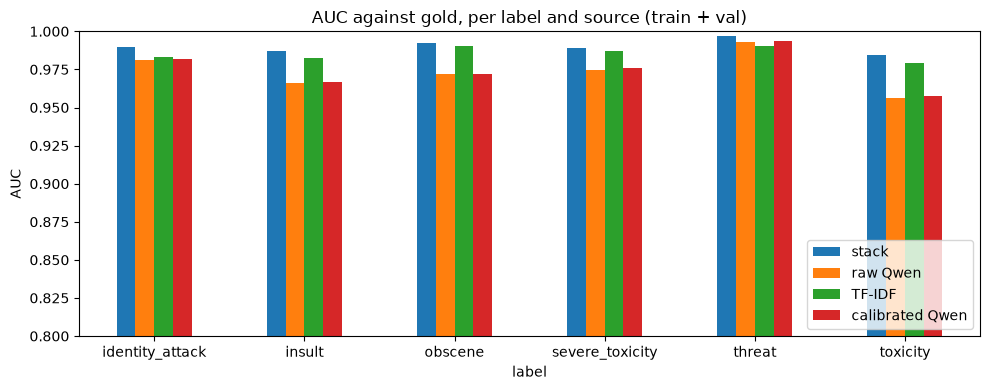

In [5]:
label_table = by_label(df)
display(label_table)

auc = label_table["AUC"].unstack("source")[list(SOURCES)]
ax = auc.plot(kind="bar", figsize=(10, 4), ylim=(0.8, 1.0), rot=0)
ax.set_title("AUC against gold, per label and source (train + val)")
ax.set_ylabel("AUC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "auc_by_label.png", dpi=150)
plt.show()

## 2. By comment length
Length bands as in the data pipeline's bias slices: under 100, 100–499, and 500+ characters. Measured on `toxicity`.

n  gold rate    AUC  PR-AUC  disagree@0.5  \
slice         source                                                           
< 100 chars   stack            41197      0.155  0.989   0.952         0.039   
              raw Qwen         41197      0.155  0.970   0.862         0.096   
              TF-IDF           41197      0.155  0.983   0.940         0.044   
              calibrated Qwen  41197      0.155  0.971   0.878         0.071   
100-499 chars stack            81542      0.083  0.983   0.878         0.034   
              raw Qwen         81542      0.083  0.960   0.688         0.143   
              TF-IDF           81542      0.083  0.978   0.865         0.036   
              calibrated Qwen  81542      0.083  0.961   0.748         0.051   
500+ chars    stack            31012      0.055  0.975   0.783         0.031   
              raw Qwen         31012      0.055  0.941   0.450         0.193   
              TF-IDF           31012      0.055  0.970   0.774         0.030   
              calibrated Qwen  31012      0.055  0.946   0.602         0.067   

                               false alarm   miss  mean |score - gold|  
slice         source                                                    
< 100 chars   stack                  0.011  0.192                0.059  
              raw Qwen               0.101  0.072                0.096  
              TF-IDF                 0.011  0.223                0.066  
              calibrated Qwen        0.012  0.395                0.112  
100-499 chars stack                  0.010  0.296                0.051  
              raw Qwen               0.150  0.064                0.143  
              TF-IDF                 0.007  0.357                0.052  
              calibrated Qwen        0.025  0.349                0.091  
500+ chars    stack                  0.012  0.348                0.045  
              raw Qwen               0.201  0.070                0.194  
              TF-IDF                 0.008  0.409                0.041  
              calibrated Qwen        0.055  0.273                0.100

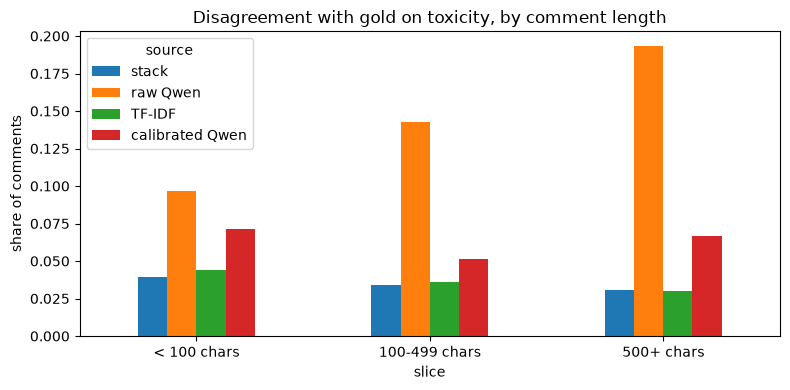

In [6]:
length_slices = {
    "< 100 chars": df["char_len"] < 100,
    "100-499 chars": df["char_len"].between(100, 499),
    "500+ chars": df["char_len"] >= 500,
}
length_table = by_slice(df, length_slices)
display(length_table)

ax = length_table["disagree@0.5"].unstack("source")[list(SOURCES)].loc[list(length_slices)].plot(
    kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Disagreement with gold on toxicity, by comment length")
ax.set_ylabel("share of comments")
plt.tight_layout()
plt.savefig(FIG_DIR / "disagreement_by_length.png", dpi=150)
plt.show()

## 3. By identity mention
`has_identity_term` from preprocess: a whole-word match on `config/identity_terms.txt`. The **false alarm** column is the bias-relevant one: clean comments that mention an identity group and still get flagged.

n  gold rate    AUC  PR-AUC  \
slice             source                                              
mentions identity stack             10624      0.171  0.969   0.892   
                  raw Qwen          10624      0.171  0.903   0.608   
                  TF-IDF            10624      0.171  0.965   0.884   
                  calibrated Qwen   10624      0.171  0.906   0.666   
no identity term  stack            143127      0.091  0.985   0.904   
                  raw Qwen         143127      0.091  0.960   0.699   
                  TF-IDF           143127      0.091  0.980   0.891   
                  calibrated Qwen  143127      0.091  0.961   0.741   

                                   disagree@0.5  false alarm   miss  \
slice             source                                              
mentions identity stack                   0.067        0.028  0.256   
                  raw Qwen                0.248        0.283  0.081   
                  TF-IDF                  0.069        0.022  0.297   
                  calibrated Qwen         0.130        0.079  0.376   
no identity term  stack                   0.032        0.010  0.257   
                  raw Qwen                0.133        0.139  0.067   
                  TF-IDF                  0.034        0.007  0.306   
                  calibrated Qwen         0.055        0.024  0.358   

                                   mean |score - gold|  
slice             source                                
mentions identity stack                          0.095  
                  raw Qwen                       0.248  
                  TF-IDF                         0.093  
                  calibrated Qwen                0.178  
no identity term  stack                          0.049  
                  raw Qwen                       0.132  
                  TF-IDF                         0.051  
                  calibrated Qwen                0.092

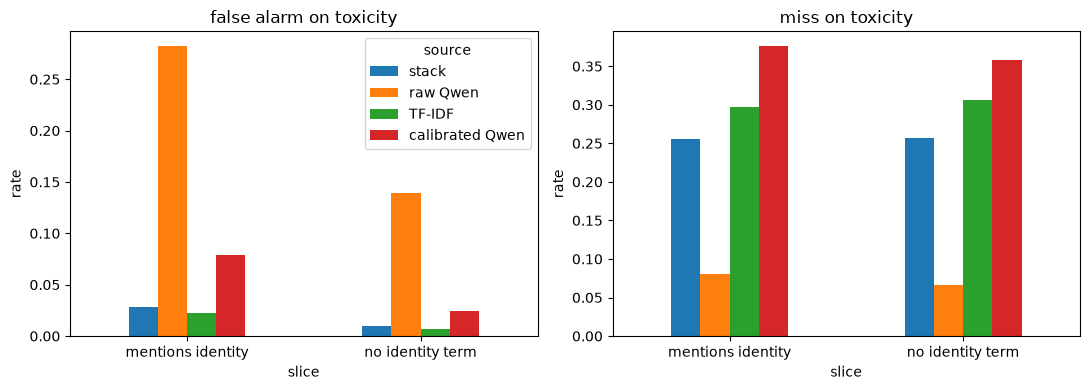

False-alarm gap, identity minus no identity (points):
source
stack               1.81
raw Qwen           14.34
TF-IDF              1.50
calibrated Qwen     5.42
Name: false alarm, dtype: float64


In [7]:
identity = df["has_identity_term"].astype(bool)
identity_slices = {"mentions identity": identity, "no identity term": ~identity}
identity_table = by_slice(df, identity_slices)
display(identity_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["false alarm", "miss"]):
    identity_table[metric].unstack("source")[list(SOURCES)].loc[list(identity_slices)].plot(
        kind="bar", ax=ax, rot=0, legend=(metric == "false alarm"))
    ax.set_title(f"{metric} on toxicity")
    ax.set_ylabel("rate")
plt.tight_layout()
plt.savefig(FIG_DIR / "identity_false_alarm_miss.png", dpi=150)
plt.show()

gap = (identity_table.xs("mentions identity")["false alarm"]
       - identity_table.xs("no identity term")["false alarm"]) * 100
print("False-alarm gap, identity minus no identity (points):")
print(gap.round(2))

## 4. Calibration
A calibrated source's predicted probability matches the observed toxic rate: points on the diagonal.

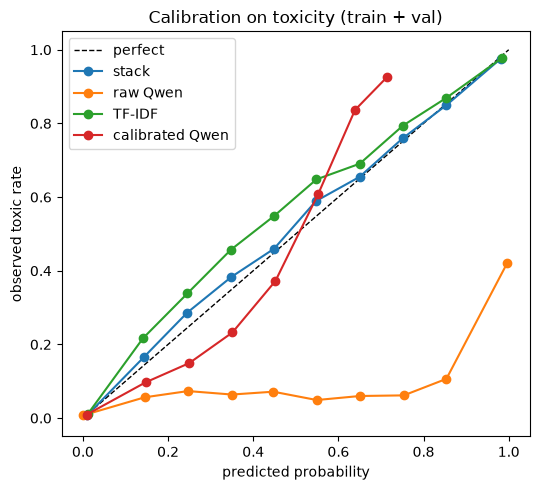

In [8]:
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="perfect")
for name, col in SOURCES.items():
    s = df[col.format("toxicity")]
    groups = pd.cut(s, bins, include_lowest=True)
    curve = df.groupby(groups, observed=True).agg(pred=(col.format("toxicity"), "mean"),
                                                  gold=("toxicity", "mean"))
    ax.plot(curve["pred"], curve["gold"], marker="o", label=name)
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed toxic rate")
ax.set_title("Calibration on toxicity (train + val)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_toxicity.png", dpi=150)
plt.show()

## 5. Truncation share
The student's maximum length is 128 tokens, with 256 to be checked once EDA shows the truncation share (v4). Tokenizer: `distilbert-base-uncased`.

In [9]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
lengths = np.array([len(ids) for ids in
                    tokenizer(df["text"].tolist(), add_special_tokens=True)["input_ids"]])
df["n_tokens"] = lengths

truncation = pd.DataFrame({
    "max length": [128, 256],
    "share truncated (all)": [(lengths > 128).mean(), (lengths > 256).mean()],
    "share truncated (toxic)": [(lengths[df["toxicity"] == 1] > n).mean() for n in (128, 256)],
})
print("median tokens:", int(np.median(lengths)), "| 95th percentile:",
      int(np.percentile(lengths, 95)))
truncation

c:\Users\Praniti\Desktop\Distillate\Model-Pipeline\.venv-model\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (660 > 512). Running this sequence through the model will result in indexing errors


median tokens: 51 | 95th percentile: 299


,max length,share truncated (all),share truncated (toxic)
0,128,0.183,0.112
1,256,0.064,0.041


## Findings

- **By label (ranking):** the stack has the highest AUC and PR-AUC on every label (mean AUC 0.990), with TF-IDF close behind (0.985) and raw Qwen lowest (0.974). These match the teacher lane's reported results, so the merged labels reproduce its outputs. Calibrated Qwen ranks like raw Qwen (toxicity AUC 0.957 vs 0.956), as expected from a calibration.
- **Rare labels:** PR-AUC separates the sources most where positives are rare: severe_toxicity 0.462 (stack) vs 0.211 (raw Qwen), threat 0.589 vs 0.272, identity_attack 0.579 vs 0.359. The stack's advantage over Qwen is largest exactly on the rarest, most serious labels.
- **Calibration:** the stack's mean score matches the gold rate on all six labels (toxicity 0.096 vs 0.096, threat 0.003 vs 0.003). Raw Qwen over-predicts every label except obscene: toxicity 0.224 vs 0.096 (about 2.3×), severe_toxicity 0.114 vs 0.010 (about 11×), threat 0.022 vs 0.003; on obscene it is about right (0.052 vs 0.053), consistent with the prompt's obscene follow-up. Calibrated Qwen brings every label close to gold; TF-IDF is slightly low (toxicity 0.090).
- **At a 0.5 cut-off:** raw Qwen over-flags (toxicity false-alarm rate 14.8%, miss rate 6.8%), while calibrated sources rarely reach 0.5 on rare labels (calibrated Qwen misses all threat and severe_toxicity comments at 0.5, despite AUCs of 0.994 and 0.976). A fixed 0.5 is therefore not a fair comparison for rare labels; the student uses per-label thresholds tuned on validation.
- **By length (toxicity):** longer comments are harder for every source. Short comments (under 100 characters) are the most often toxic (15.5%, vs 8.3% for 100–499 and 5.5% for 500+) and the easiest: stack PR-AUC 0.952, falling to 0.878 and 0.783 for long comments, with the stack's miss rate rising from 19.2% to 29.6% and 34.8%. Raw Qwen degrades most with length: its PR-AUC drops from 0.862 to 0.450 and its false-alarm rate doubles, from 10.1% to 20.1%, so it over-flags long, mostly clean comments.
- **By identity mention (toxicity):** comments that mention an identity term (10,624, 6.9%) are gold-toxic almost twice as often as others (17.1% vs 9.1%), a data-level gap the model could learn as a shortcut. Raw Qwen shows a strong identity bias: on clean comments, it flags 28.3% of those mentioning an identity versus 13.9% of the rest (a gap of +14.4 points), and its AUC drops from 0.960 to 0.903. The stack shrinks that false-alarm gap to +1.8 points (2.8% vs 1.0%; TF-IDF +1.5, calibrated Qwen +5.5), with the same miss rate on both slices (25.6% vs 25.7%). The identity slice relies on the approximate identity lexicon, so these are indicative.
- **Truncation (distilbert-base-uncased):** the median comment is 51 tokens and the 95th percentile 299. At max length 128, 18.3% of train+val comments are truncated, but only 11.2% of toxic ones (toxic comments tend to be shorter); at 256 that falls to 6.4% and 4.1%.
- **For the student:** train on the stack (`p_<label>`): it is the best-ranked and best-calibrated source on every label, and it inherits far less of raw Qwen's identity bias and long-comment over-flagging. Use per-label thresholds rather than 0.5, since calibrated scores on rare labels rarely reach 0.5. On max length, 128 keeps the full text of almost 9 in 10 toxic comments; 256 recovers about 7 more in 100 at a higher CPU cost, and long comments are where every source is weakest, so the deciding test is toxic recall on validation at 128 vs 256, against the CPU latency budget. The student's bias check should still watch identity-mentioning comments, where even the stack's false-alarm rate is almost three times higher.